# Checkpoint 1 — Pipeline de entrenamiento, validación y clasificador base

Notebook autocontenido (corre igual en local o en Colab). La versión modular del mismo pipeline está en `src/`.
Cada celda tiene su resumen **Qué hace** y las anotaciones línea por línea con `→`.

### Celda 1 — Configuración del entorno

**Qué hace:** importa las librerías, fija las semillas de aleatoriedad y detecta automáticamente el dispositivo (CUDA, MPS o CPU).

- `→ seed_everything(42)` — fija `random`, `numpy` y `torch` para que los resultados sean reproducibles.
- `→ torch.cuda.manual_seed_all` — fija también la semilla de todas las GPUs, solo si hay CUDA.
- `→ device = ...` — elige CUDA > MPS > CPU; todo tensor y modelo se mueve luego con `.to(device)`.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

def seed_everything(seed=42):
    random.seed(seed)                      # semilla de Python
    np.random.seed(seed)                   # semilla de NumPy
    torch.manual_seed(seed)                # semilla de PyTorch (CPU)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)   # semilla de PyTorch (todas las GPUs)

seed_everything(42)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch {torch.__version__} | dispositivo: {device}")

PyTorch 2.15.0+cu132 | dispositivo: cpu


### Celda 2 — Dataset y DataLoaders

**Qué hace:** genera un dataset sintético de clasificación binaria (5000 muestras, 20 variables), lo parte en train/validación (80/20, estratificado), estandariza y arma los `DataLoader`.

- `→ make_classification(...)` — crea 5000 filas con 20 features (15 informativas, 2 redundantes) y 2 clases.
- `→ train_test_split(..., stratify=y)` — separa 20 % para validación manteniendo la proporción de clases.
- `→ scaler.fit_transform(X_train)` — el `StandardScaler` se ajusta **solo con train**, para no filtrar información de validación (data leakage).
- `→ scaler.transform(X_val)` — aplica a validación la media y desvío calculados en train.
- `→ torch.tensor(..., dtype=torch.long)` — las etiquetas deben ser `long` para `CrossEntropyLoss`.
- `→ shuffle=True` solo en train — validación no necesita mezclarse.

In [2]:
X, y = make_classification(n_samples=5000, n_features=20, n_informative=15,
                           n_redundant=2, n_classes=2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                         torch.tensor(y_train, dtype=torch.long))
val_ds = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                       torch.tensor(y_val, dtype=torch.long))

g = torch.Generator().manual_seed(42)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

print(f"Train: {len(train_ds)} | Validación: {len(val_ds)}")

Train: 4000 | Validación: 1000


### Celda 3 — Arquitectura base (MLP)

**Qué hace:** define un `nn.Module` con un MLP de dos capas ocultas (64 y 32 neuronas) con ReLU, que devuelve logits de 2 clases.

- `→ nn.Linear(input_dim, 64)` — primera capa densa: 20 → 64.
- `→ nn.ReLU()` — no linealidad entre capas (sin ella, el MLP colapsaría a un modelo lineal).
- `→ nn.Linear(32, 2)` — salida con 2 logits, sin softmax: `CrossEntropyLoss` lo aplica internamente.
- `→ .to(device)` — mueve los parámetros al dispositivo elegido.

In [3]:
class BaselineClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes),
        )

    def forward(self, x):
        return self.network(x)

model = BaselineClassifier(input_dim=20).to(device)
print(model)
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BaselineClassifier(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)
Parámetros entrenables: 3490


### Celda 4 — Funciones de entrenamiento y evaluación

**Qué hace:** define una época de entrenamiento (forward, pérdida, backward, update) y una función de evaluación que calcula pérdida, accuracy y F1 sobre validación.

- `→ model.train()` — activa el modo entrenamiento (relevante para dropout/batchnorm si se agregan después).
- `→ optimizer.zero_grad()` — reinicia los gradientes; PyTorch los acumula por defecto.
- `→ outputs = model(inputs)` — forward pass.
- `→ loss = criterion(outputs, targets)` — pérdida de entropía cruzada.
- `→ loss.backward()` — backward pass: `autograd` calcula el gradiente de la pérdida respecto de cada parámetro.
- `→ optimizer.step()` — Adam actualiza los pesos con esos gradientes.
- `→ loss.item() * inputs.size(0)` — acumula la pérdida ponderada por el tamaño del batch (el último puede ser menor).
- `→ @torch.no_grad()` — en evaluación no se construye el grafo de gradientes: ahorra memoria y tiempo.
- `→ model.eval()` — modo evaluación.
- `→ argmax(dim=1)` — la clase predicha es el logit más alto.

In [4]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        correct += (outputs.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_targets = [], []
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        preds = outputs.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        correct += (preds == targets).sum().item()
        total += targets.size(0)
        all_preds.append(preds.cpu())
        all_targets.append(targets.cpu())
    f1 = f1_score(torch.cat(all_targets).numpy(), torch.cat(all_preds).numpy())
    return running_loss / total, correct / total, f1

### Celda 5 — Entrenamiento con tracking por época

**Qué hace:** entrena 30 épocas con Adam (`learning_rate = 0.001`) y registra pérdida y métricas de train y validación en cada época.

- `→ criterion = nn.CrossEntropyLoss()` — pérdida estándar para clasificación con logits.
- `→ optim.Adam(model.parameters(), lr=learning_rate)` — optimizador Adam sobre todos los parámetros del modelo.
- `→ history = {...}` — diccionario donde se guarda cada métrica por época.
- `→ best_val_loss` — se usa para quedarse con los pesos de la mejor época de validación.
- `→ copy.deepcopy(model.state_dict())` — copia independiente de los pesos (un `state_dict()` simple es una referencia que se seguiría actualizando).

In [5]:
import copy

learning_rate = 0.001
epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
best_val_loss, best_state = float("inf"), None

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc, va_f1 = evaluate(model, val_loader, criterion, device)

    for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, va_f1]):
        history[k].append(v)

    if va_loss < best_val_loss:
        best_val_loss, best_state = va_loss, copy.deepcopy(model.state_dict())

    print(f"Época [{epoch:02d}/{epochs}] | Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | "
          f"Val Loss: {va_loss:.4f} Acc: {va_acc*100:.2f}% F1: {va_f1:.4f}")

Época [01/30] | Train Loss: 0.5551 Acc: 76.62% | Val Loss: 0.3892 Acc: 84.80% F1: 0.8504
Época [02/30] | Train Loss: 0.3129 Acc: 87.85% | Val Loss: 0.2299 Acc: 91.30% F1: 0.9136
Época [03/30] | Train Loss: 0.2075 Acc: 92.30% | Val Loss: 0.1683 Acc: 93.60% F1: 0.9361
Época [04/30] | Train Loss: 0.1586 Acc: 94.55% | Val Loss: 0.1466 Acc: 94.90% F1: 0.9502


Época [05/30] | Train Loss: 0.1305 Acc: 95.75% | Val Loss: 0.1287 Acc: 95.60% F1: 0.9567
Época [06/30] | Train Loss: 0.1130 Acc: 96.20% | Val Loss: 0.1101 Acc: 96.10% F1: 0.9610
Época [07/30] | Train Loss: 0.0998 Acc: 97.00% | Val Loss: 0.1085 Acc: 96.00% F1: 0.9607
Época [08/30] | Train Loss: 0.0918 Acc: 97.35% | Val Loss: 0.1059 Acc: 95.90% F1: 0.9591


Época [09/30] | Train Loss: 0.0825 Acc: 97.75% | Val Loss: 0.0978 Acc: 96.10% F1: 0.9617
Época [10/30] | Train Loss: 0.0784 Acc: 97.75% | Val Loss: 0.1006 Acc: 95.70% F1: 0.9577
Época [11/30] | Train Loss: 0.0733 Acc: 98.05% | Val Loss: 0.0940 Acc: 96.60% F1: 0.9663
Época [12/30] | Train Loss: 0.0688 Acc: 97.78% | Val Loss: 0.0966 Acc: 96.00% F1: 0.9602


Época [13/30] | Train Loss: 0.0639 Acc: 98.20% | Val Loss: 0.0940 Acc: 96.00% F1: 0.9606
Época [14/30] | Train Loss: 0.0598 Acc: 98.40% | Val Loss: 0.0922 Acc: 96.30% F1: 0.9633
Época [15/30] | Train Loss: 0.0574 Acc: 98.42% | Val Loss: 0.0934 Acc: 96.00% F1: 0.9603
Época [16/30] | Train Loss: 0.0553 Acc: 98.60% | Val Loss: 0.0955 Acc: 96.30% F1: 0.9629


Época [17/30] | Train Loss: 0.0544 Acc: 98.52% | Val Loss: 0.0853 Acc: 96.60% F1: 0.9661
Época [18/30] | Train Loss: 0.0510 Acc: 98.70% | Val Loss: 0.0965 Acc: 95.80% F1: 0.9583
Época [19/30] | Train Loss: 0.0484 Acc: 98.78% | Val Loss: 0.0970 Acc: 96.20% F1: 0.9621


Época [20/30] | Train Loss: 0.0469 Acc: 98.72% | Val Loss: 0.1027 Acc: 95.90% F1: 0.9596
Época [21/30] | Train Loss: 0.0435 Acc: 98.88% | Val Loss: 0.0918 Acc: 96.80% F1: 0.9681
Época [22/30] | Train Loss: 0.0421 Acc: 98.83% | Val Loss: 0.0942 Acc: 96.40% F1: 0.9641
Época [23/30] | Train Loss: 0.0413 Acc: 98.90% | Val Loss: 0.0890 Acc: 96.50% F1: 0.9650


Época [24/30] | Train Loss: 0.0374 Acc: 99.02% | Val Loss: 0.0852 Acc: 96.70% F1: 0.9670
Época [25/30] | Train Loss: 0.0373 Acc: 99.05% | Val Loss: 0.0865 Acc: 96.90% F1: 0.9689
Época [26/30] | Train Loss: 0.0349 Acc: 99.20% | Val Loss: 0.1006 Acc: 96.20% F1: 0.9621
Época [27/30] | Train Loss: 0.0343 Acc: 99.12% | Val Loss: 0.0893 Acc: 97.10% F1: 0.9711


Época [28/30] | Train Loss: 0.0312 Acc: 99.35% | Val Loss: 0.0891 Acc: 97.00% F1: 0.9699
Época [29/30] | Train Loss: 0.0294 Acc: 99.42% | Val Loss: 0.0921 Acc: 96.80% F1: 0.9681
Época [30/30] | Train Loss: 0.0297 Acc: 99.38% | Val Loss: 0.0977 Acc: 96.40% F1: 0.9641


### Celda 6 — Curvas de pérdida y accuracy

**Qué hace:** grafica la evolución de la pérdida y del accuracy en train y validación para detectar overfitting.

- `→ ax[0]` — curva de pérdida: si train sigue bajando y validación se aplana o sube, hay overfitting.
- `→ ax[1]` — curva de accuracy de train y validación.
- `→ best_val_loss` — mejor pérdida de validación y la época en que ocurrió.

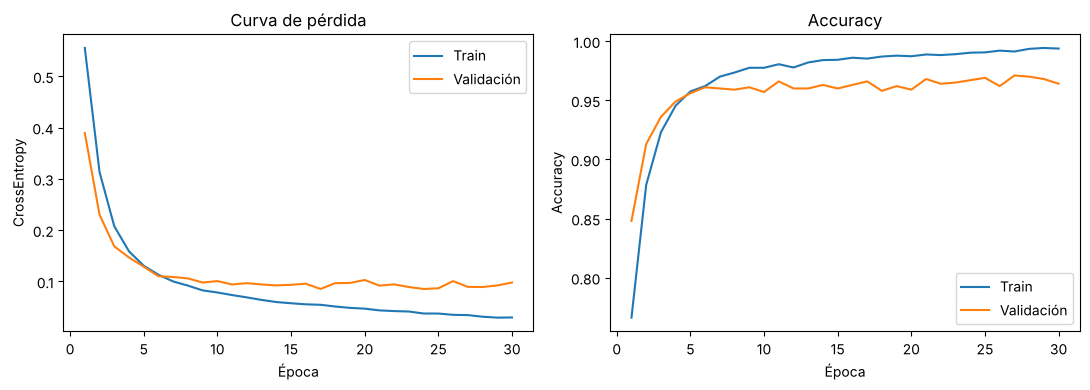

Mejor val loss: 0.0852 (época 24)


In [6]:
ep = range(1, epochs + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, history["train_loss"], label="Train")
ax[0].plot(ep, history["val_loss"], label="Validación")
ax[0].set(title="Curva de pérdida", xlabel="Época", ylabel="CrossEntropy"); ax[0].legend()
ax[1].plot(ep, history["train_acc"], label="Train")
ax[1].plot(ep, history["val_acc"], label="Validación")
ax[1].set(title="Accuracy", xlabel="Época", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Mejor val loss: {best_val_loss:.4f} (época {best_epoch})")